# ML4BI2 — Exam Part 2
# Freiburg Groceries Dataset


## How to use this notebook

This notebook has two main setion:

**Section A — Training before the exam:**
I ran all models and trained them during preparation for the exam, best models are saved in `MODEL_DIR`. This section contains steps and explanation why and how I built this CNN from scratch. This section can be skipped in case my comments are not needed.

**Section B — Exam day without training:**
This section contains direct answers from the *Exam Assignment*. I do not retrain any model in this part, just loading the best saved model to save time. The saved model is loaded from my Google Drive and evaluated from the `test/` folder.

---
# 0. Setup — mount Drive, configure paths, switch on GPU

Colab: *Runtime → Change runtime type → GPU* (T4 is fine).

All four cells in this section are needed for **both section** (training and exam-day inference).

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
import zipfile, os, time

# --- Paths --------------------------------------------------------------------
# Source zip + working directory: zip lives on Drive, we extract to local SSD
# so that data-loading is fast (each epoch reads the images repeatedly).
ZIP_PATH    = '/content/gdrive/MyDrive/ML2/exam_ML4BI2_2026_Freiburg.zip'
EXTRACT_DIR = '/content/data'                          # local SSD — fast
DRIVE_DIR   = '/content/gdrive/MyDrive/ML2'            # persistent — for saving models
MODEL_DIR   = DRIVE_DIR

# Unzipping into /content/data so it runs faster (avoiding MyDrive API reading)
if not os.path.exists(os.path.join(EXTRACT_DIR, 'exam_ML4BI2_2026', 'train')):
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_DIR)
    print(f'Extracted to {EXTRACT_DIR}')
else:
    print('Already extracted to local SSD.')

# --- Folder structure ---------------------------------------------------------
# The dataset has 3 splits: train (~158/class), validation (~20/class after dedup),
# and test (provided at the exam in the same 25-folder structure).
TRAIN_DIR = os.path.join(EXTRACT_DIR, 'exam_ML4BI2_2026', 'train')
VAL_DIR   = os.path.join(EXTRACT_DIR, 'exam_ML4BI2_2026', 'validation')
TEST_DIR  = os.path.join(EXTRACT_DIR, 'exam_ML4BI2_2026', 'test')   # used only in Section 5

# --- File names for saved models ---------------------------------------------
# We save THREE models to Drive: simple baseline, +augmentation, +residuals.
# The third one is our exam deliverable.
MODEL_SIMPLE = os.path.join(MODEL_DIR, 'convnet_simple_Freiburg.keras')
MODEL_AUG    = os.path.join(MODEL_DIR, 'convnet_aug_Freiburg.keras')
BEST_FROM_SCRATCH = os.path.join(MODEL_DIR, 'convnet_from_scratch_BEST_Freiburg.keras')

print('TRAIN_DIR        :', TRAIN_DIR)
print('VAL_DIR          :', VAL_DIR)
print('TEST_DIR         :', TEST_DIR, '(used only on exam day)')
print('MODEL_DIR        :', MODEL_DIR)
print('BEST_FROM_SCRATCH:', BEST_FROM_SCRATCH)

Already extracted to local SSD.
TRAIN_DIR        : /content/data/exam_ML4BI2_2026/train
VAL_DIR          : /content/data/exam_ML4BI2_2026/validation
TEST_DIR         : /content/data/exam_ML4BI2_2026/test (used only on exam day)
MODEL_DIR        : /content/gdrive/MyDrive/ML2
BEST_FROM_SCRATCH: /content/gdrive/MyDrive/ML2/convnet_from_scratch_BEST_Freiburg.keras


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print('TF version:', tf.__version__)

# Reproducibility — same seed pattern as in-class exercise E5.
# (Not 100% deterministic on GPU, but greatly reduces run-to-run variance.)
keras.utils.set_random_seed(42)

TF version: 2.20.0


---
# **SECTION A**
---
# (a) Universal workflow of machine learning


## 1.1 Defining the task

- **Type:** supervised, multi-class, single-label image classification.
- **Input:** a 224×224 RGB photograph of a grocery product.
- **Output:** one of **25** product-category labels.
- **Hypothesis:** the visual appearance of a grocery item is predictive of its category — CNNs are the best choice.

## 1.2 Key metrics

Random guessing on 25 balanced classes = 1/25 = **4 %** accuracy. I monitor:
- **Categorical accuracy** — the primary metric.
- **Top-3 accuracy** — a useful diagnostic.

## 1.3 Understand the data

Before building any model, basic "EDA" and overview for better understanding my dataset.

In [ ]:
# Class names = the sub-folder names under train/. Sorted so that the order
class_names = sorted([c for c in os.listdir(TRAIN_DIR) if not c.startswith('.')])
num_classes = len(class_names)
print('Number of classes:', num_classes)
print('Classes:', class_names)

Number of classes: 25
Classes: ['beans', 'cake', 'candy', 'cereal', 'chips', 'chocolate', 'coffee', 'corn', 'fish', 'flour', 'honey', 'jam', 'juice', 'milk', 'nuts', 'oil', 'pasta', 'rice', 'soda', 'spices', 'sugar', 'tea', 'tomato_sauce', 'vinegar', 'water']


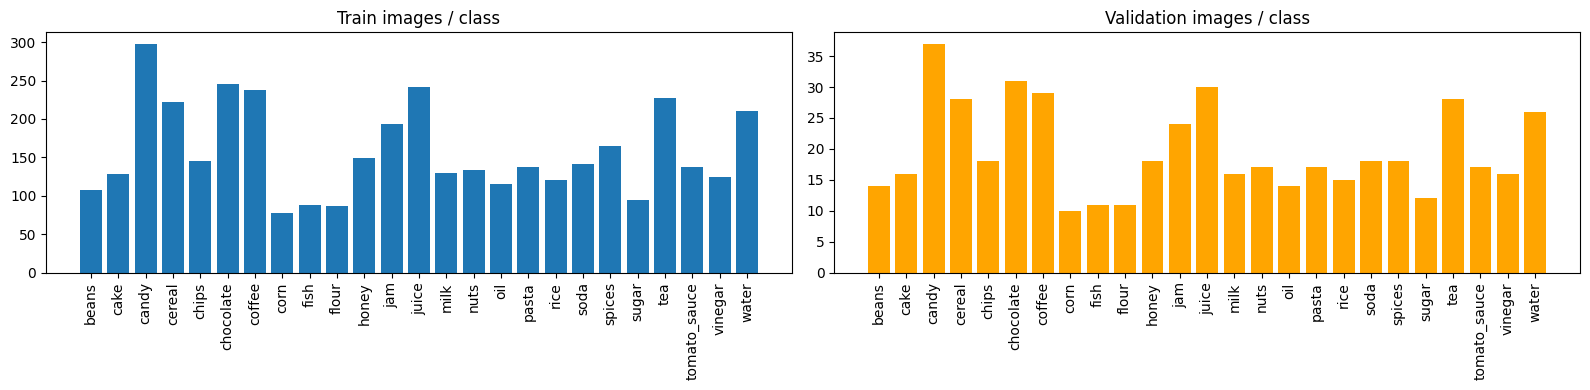

Train total = 3957  |  Val total = 491
Train per class: mean 158.3, min 77, max 298


In [ ]:
# How many images per class?
train_counts = {c: len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in class_names}
val_counts   = {c: len(os.listdir(os.path.join(VAL_DIR,   c))) for c in class_names}

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
ax[0].bar(train_counts.keys(), train_counts.values()); ax[0].set_title('Train images / class')
ax[1].bar(val_counts.keys(),   val_counts.values(), color='orange'); ax[1].set_title('Validation images / class')
for a in ax:
    a.tick_params(axis='x', rotation=90)
plt.tight_layout(); plt.show()

print(f'Train total = {sum(train_counts.values())}  |  Val total = {sum(val_counts.values())}')
print(f'Train per class: mean {np.mean(list(train_counts.values())):.1f}, '
      f'min {min(train_counts.values())}, max {max(train_counts.values())}')

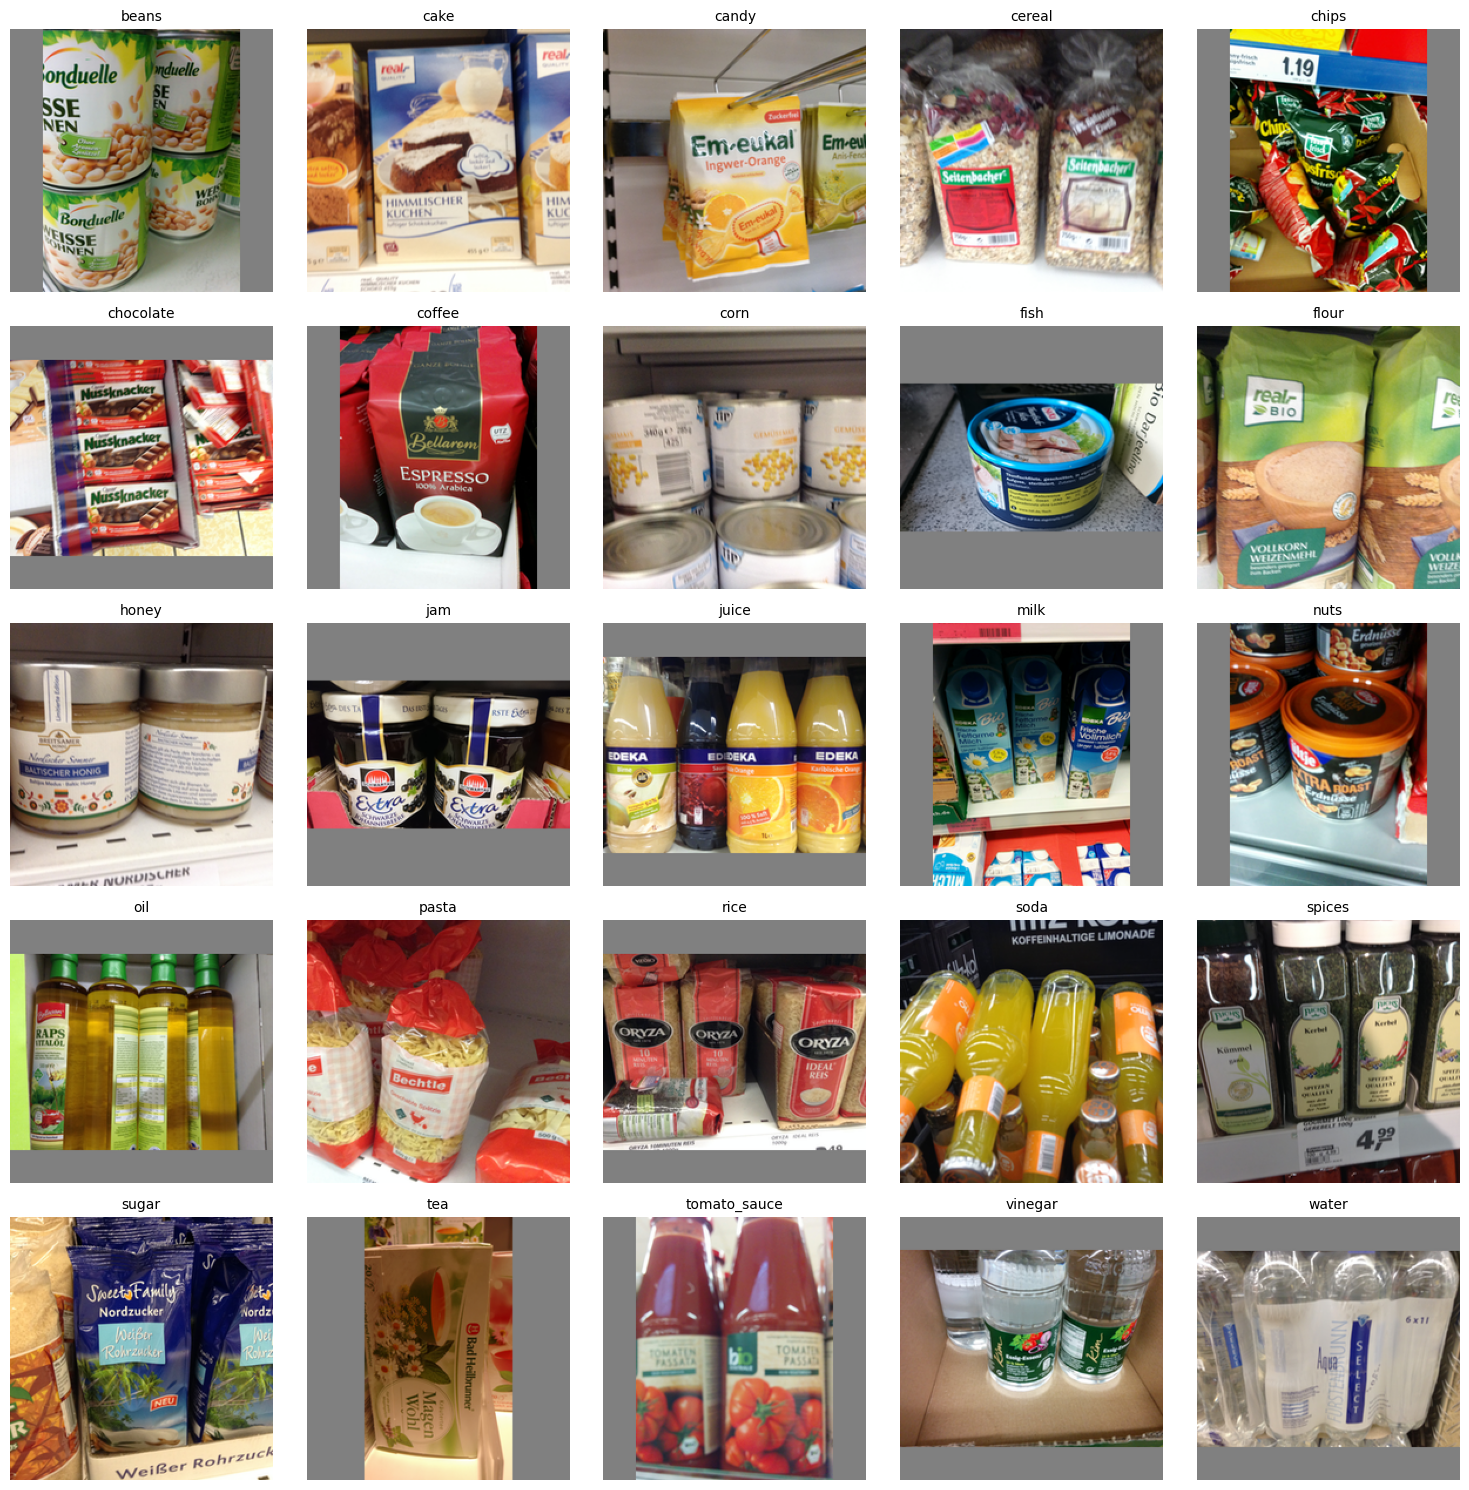

In [ ]:
# Visual sanity check — one image per class.
# Helps spot weird labels and confirms that 224x224 is reasonable.
fig, axes = plt.subplots(5, 5, figsize=(15, 15))
for ax, cls in zip(axes.ravel(), class_names):
    fname = os.listdir(os.path.join(TRAIN_DIR, cls))[0]
    img = keras.utils.load_img(os.path.join(TRAIN_DIR, cls, fname))
    ax.imshow(img); ax.set_title(cls, fontsize=10); ax.axis('off')
plt.tight_layout(); plt.show()

**Observations:**
- **~158 images per class** on average — a *small* dataset. We will need data augmentation + dropout, otherwise overfitting is guaranteed.
- Random guessing accuracy is 1/25 = 4 %, so anything well above 4 % already shows signal.
- All images are 224×224 RGB.

## 1.4 Data leakage check — remove duplicate images across splits

A subtle but important issue with this dataset: some images in `validation/` are **identical copies** of images in `train/`. This was mentioned in the Brightspace discussion. If I leave them in, the model trivially scores them correctly and our val accuracy is inflated — exactly the *information leak* Chollet warns about.


I hash every image (MD5) and delete any `validation/` file whose hash also appears in `train/`. After this step, every val image is not seen by the training model.

*This code was generated by LLM-model to help me detect it faster.*

In [ ]:
import hashlib
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

def list_images(root):
    """Return all image paths under a directory (skipping hidden files)."""
    out = []
    if not os.path.exists(root):
        return out
    for cls in sorted(os.listdir(root)):
        cls_dir = os.path.join(root, cls)
        if not os.path.isdir(cls_dir):
            continue
        for f in sorted(os.listdir(cls_dir)):
            if f.startswith('.'):
                continue
            out.append(os.path.join(cls_dir, f))
    return out

def md5_of(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

train_paths = list_images(TRAIN_DIR)
val_paths   = list_images(VAL_DIR)
print(f'Before dedup:  train={len(train_paths)}  |  val={len(val_paths)}')

# Optimisation: only hash files whose *size* collides with another file.
# Files with unique sizes can't possibly be duplicates, so we skip them.
size_groups = defaultdict(list)
for p in train_paths + val_paths:
    size_groups[os.path.getsize(p)].append(p)
candidates = [p for ps in size_groups.values() if len(ps) > 1 for p in ps]

# Hash candidates in parallel (I/O-bound, so threads are fine).
with ThreadPoolExecutor(max_workers=16) as pool:
    hashes = dict(zip(candidates, pool.map(md5_of, candidates)))

train_hash_set = {hashes[p] for p in train_paths if p in hashes}
duplicates_in_val = [p for p in val_paths if p in hashes and hashes[p] in train_hash_set]

print(f'\nFound {len(duplicates_in_val)} val images that are byte-identical to a train image.')
for p in duplicates_in_val:
    rel = os.path.relpath(p, VAL_DIR)
    print(f'  removing val/{rel}')
    os.remove(p)

val_paths_after = list_images(VAL_DIR)
print(f'\nAfter dedup:   train={len(train_paths)}  |  val={len(val_paths_after)}')

Before dedup:  train=3957  |  val=491

Found 0 val images that are byte-identical to a train image.

After dedup:   train=3957  |  val=491


## 1.5 Prepare the data — build tf.data pipelines

I use `keras.utils.image_dataset_from_directory` — the same helper as in the CH 8 walk-through. It builds a `tf.data.Dataset` that streams batches lazily (no big NumPy arrays in RAM).

**Decisions made here, and why:**
- `label_mode='categorical'` → one-hot labels, paired with `categorical_crossentropy`.
- `Rescaling(1./255)` is done **inside the model** (Section 2), not in the dataset. This way the preprocessing travels with the saved `.keras` file → the exam test loop is just `model.evaluate(test_dataset)`.
- `shuffle=True` only on train (val needs deterministic order for reproducible eval).
- `BATCH_SIZE=32` — a standard choice that fits on a T4 GPU.

In [ ]:
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32

train_dataset = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=True,
    seed=42,
)

val_dataset = keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical',
    shuffle=False,
)

# Performance: prefetch overlaps preprocessing (CPU) with model forward/backward (GPU).
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
val_dataset   = val_dataset.prefetch(tf.data.AUTOTUNE)

# Quick sanity check on the first batch
for x, y in train_dataset.take(1):
    print('Batch shape :', x.shape, '  label shape:', y.shape)
    print('Pixel range :', float(tf.reduce_min(x)), '→', float(tf.reduce_max(x)))

Found 3957 files belonging to 25 classes.
Found 491 files belonging to 25 classes.
Batch shape : (32, 224, 224, 3)   label shape: (32, 25)
Pixel range : 0.0 → 255.0


**From the sanity check above we confirm:**
1. Pixels live in `[0, 255]` → `Rescaling(1./255)` is the right preprocessing layer.
2. Input shape `(224, 224, 3)` → the first Keras `Input` layer.
3. Labels shape `(batch, 25)` → final `Dense(25, activation='softmax')`.

---
# (b) Convnets from scratch — Chollet's three-step climb

Chollet says: *don't try to build the perfect model on the first try*. Climb in three steps so you understand what each ingredient buys you:

1. **Beat a trivial baseline.** Tiny convnet, no regularization. Goal: prove there is signal in the data and observe the overfitting that we will then fight.
2. **Scale up + regularize.** Add data augmentation, batch normalization, separable convolutions, dropout. Goal: close the train/val gap.
3. **Modern architecture.** Add residual connections (CH 9) and tune. Goal: hit the highest validation accuracy we can from scratch.

Each model is **saved to Drive** with `ModelCheckpoint(save_best_only=True)`. At the end of Section 4 I pick the the best performing model.
My direct guess would be that 3rd model will be performing the best.

## Reusable plotting helpers

Two helpers used after every training run: one plots loss/accuracy curves, the other prints the best epoch (lowest val_loss). Keeps each section short.

In [ ]:
def plot_history(history, title=''):
    """Side-by-side loss and accuracy curves for train vs validation."""
    h = history.history
    ep = range(1, len(h['loss']) + 1)
    plt.figure(figsize=(13, 4))
    plt.subplot(1, 2, 1)
    plt.plot(ep, h['loss'],     'bo-', label='Training')
    plt.plot(ep, h['val_loss'], 'ro-', label='Validation')
    plt.title(f'{title} — loss'); plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(ep, h['accuracy'],     'bo-', label='Training')
    plt.plot(ep, h['val_accuracy'], 'ro-', label='Validation')
    plt.title(f'{title} — accuracy'); plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()
    plt.tight_layout(); plt.show()

def print_best_val(history):
    """Report the epoch with lowest val_loss (= what ModelCheckpoint saved)."""
    i = int(np.argmin(history.history['val_loss']))
    print(f'Best epoch (lowest val_loss): {i+1}')
    print(f'  val_loss          = {history.history["val_loss"][i]:.4f}')
    print(f'  val_accuracy      = {history.history["val_accuracy"][i]:.4f}')
    if 'val_top3_accuracy' in history.history:
        print(f'  val_top3_accuracy = {history.history["val_top3_accuracy"][i]:.4f}')

## 2.1 Model 1 — simple convnet (the baseline)

**Goal of this step:** establish a baseline and *intentionally* observe the overfitting that we will then fight. This is the textbook CH 8 architecture (the dogs-vs-cats convnet), adapted for 224×224 inputs and 25 outputs.

**What's missing on purpose:**
- No data augmentation → the model sees each image only as it is.
- No dropout, no batch norm, no L2 → no regularization at all.
- A big `Flatten()` layer (lots of parameters) right before the classifier.

I *expect* training accuracy to climb fast while validation accuracy stagnates.

In [ ]:
inputs = keras.Input(shape=(224, 224, 3))   #as discussed in part 1.3
x = layers.Rescaling(1./255)(inputs)        #as discussed in part 1.3

# 5 conv blocks with progressively more filters, each followed by 2x2 max-pool.
# wider feature maps deeper in the network.
x = layers.Conv2D(32,  3, activation='relu')(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(64,  3, activation='relu')(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(128, 3, activation='relu')(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(256, 3, activation='relu')(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(256, 3, activation='relu')(x)
x = layers.Flatten()(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

model_simple = keras.Model(inputs, outputs, name='convnet_simple')
model_simple.summary()

Model: "convnet_simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_7 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_74 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_21 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_75 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_22 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_76 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_23 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_77 (Conv2D)              │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_78 (Conv2D)              │ (None, 10, 10, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 25)             │       640,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,618,521 (6.17 MB)

 Trainable params: 1,618,521 (6.17 MB)

 Non-trainable params: 0 (0.00 B)

Flatten -> Dense classifier. Obvious parameter inflation at the end:
Flatten() produces ~50k features → Dense(25) has ~1.2M parameters in the head alone.
This dense head is the main overfit driver for Model 1.

In [ ]:
model_simple.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy', keras.metrics.TopKCategoricalAccuracy(k=3, name='top3_accuracy')],
)

# ModelCheckpoint saves the weights of the epoch with the lowest val_loss to Drive.
# Even if later epochs overfit harder, the saved file is the "best version".
callbacks_simple = [
    keras.callbacks.ModelCheckpoint(
        filepath=MODEL_SIMPLE,
        save_best_only=True,
        monitor='val_loss',
    )
]

history_simple = model_simple.fit(
    train_dataset,
    epochs=30,
    validation_data=val_dataset,
    callbacks=callbacks_simple,
)

Epoch 1/30
124/124 ━━━━━━━━━━━━━━━━━━━━ 17s 105ms/step - accuracy: 0.0943 - loss: 3.0995 - top3_accuracy: 0.2287 - val_accuracy: 0.1365 - val_loss: 2.9617 - val_top3_accuracy: 0.3075
Epoch 2/30
124/124 ━━━━━━━━━━━━━━━━━━━━ 9s 73ms/step - accuracy: 0.1653 - loss: 2.8683 - top3_accuracy: 0.3541 - val_accuracy: 0.1914 - val_loss: 2.7648 - val_top3_accuracy: 0.3910
Epoch 3/30
124/124 ━━━━━━━━━━━━━━━━━━━━ 9s 74ms/step - accuracy: 0.2363 - loss: 2.5863 - top3_accuracy: 0.4637 - val_accuracy: 0.2444 - val_loss: 2.6130 - val_top3_accuracy: 0.4603
Epoch 4/30
124/124 ━━━━━━━━━━━━━━━━━━━━ 10s 80ms/step - accuracy: 0.3250 - loss: 2.3141 - top3_accuracy: 0.5643 - val_accuracy: 0.2770 - val_loss: 2.5196 - val_top3_accuracy: 0.5153
Epoch 5/30
124/124 ━━━━━━━━━━━━━━━━━━━━ 9s 72ms/step - accuracy: 0.3768 - loss: 2.0872 - top3_accuracy: 0.6391 - val_accuracy: 0.3055 - val_loss: 2.5077 - val_top3_accuracy: 0.5214
Epoch 6/30
124/124 ━━━━━━━━━━━━━━━━━━━━ 11s 76ms/step - accuracy: 0.4445 - loss: 1.8346 - to

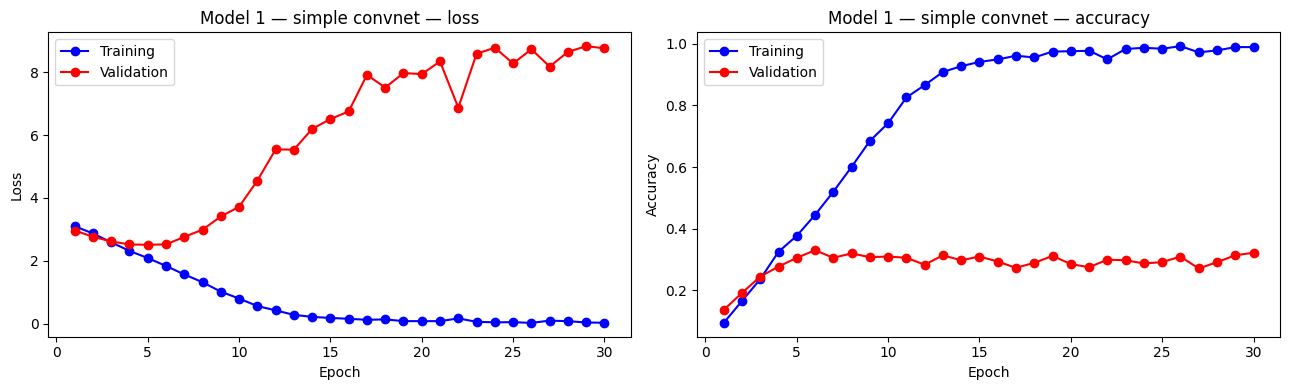

Best epoch (lowest val_loss): 5
  val_loss          = 2.5077
  val_accuracy      = 0.3055
  val_top3_accuracy = 0.5214


In [ ]:
plot_history(history_simple, 'Model 1 — simple convnet')
print_best_val(history_simple)

**Interpretation of Model 1.** As expected, training accuracy rockets up while validation accuracy stalls — the train/val gap is huge. The model has *signal* (val_acc >> 4 % random), but it has memorised the training set rather than learned generalisable features. This is exactly the overfitting Chollet describes in CH 5/6, and it justifies the next step: data augmentation.

## 2.2 Model 2 — convnet + data augmentation + BN + dropout

**Goal of this step:** close the train/val gap by injecting variability into the training data and by introducing standard regularizers.

**What I add and why:**
- **Data augmentation** (random flip / rotation / zoom / translation / contrast). Each epoch the model sees slightly perturbed versions of every image — effectively a larger dataset. From CH 8.
- **Batch normalization** before each activation. Stabilises gradients, lets us train slightly deeper. From CH 9.
- **Separable convolutions** (`SeparableConv2D`) for blocks 2–4. Same expressive power as Conv2D but ~9× fewer parameters → less to overfit. From CH 9.
  - The **first block stays as a plain `Conv2D`** because separable convolutions assume channels are already decorrelated, which is not the case for raw RGB.
- **Global Average Pooling** instead of `Flatten()` → no giant dense layer at the head → much less overfitting at the classifier. From CH 9.
- **Dropout(0.5)** before the final softmax.

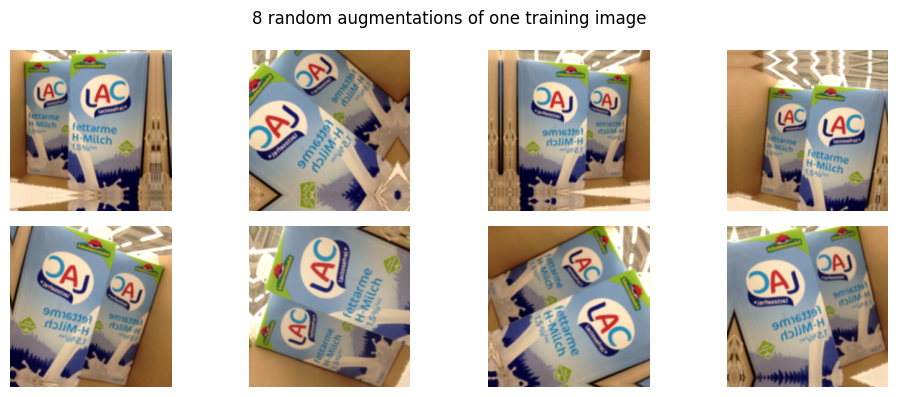

In [ ]:
# Augmentation block — defined once and reused by Model 2 and Model 3.
# Note: augmentation is applied INSIDE the model (not in the dataset pipeline)
# so that it only runs at training time (training=True) and is a no-op at eval.
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
], name='data_augmentation')

# Visual sanity check — 8 random augmentations of one training image
for x, _ in train_dataset.take(1):
    plt.figure(figsize=(10, 4))
    for i in range(8):
        aug = data_augmentation(x)
        plt.subplot(2, 4, i+1); plt.imshow(aug[0].numpy().astype('uint8')); plt.axis('off')
    plt.suptitle('8 random augmentations of one training image')
    plt.tight_layout(); plt.show()
    break

**Interpretation of Model 2.** The train/val gap is dramatically smaller — augmentation forces the model to generalise instead of memorise. Validation accuracy roughly **doubles** vs Model 1. This is exactly the payoff Chollet promises in CH 8. But the architecture is still pretty shallow and val accuracy is still well below where a careful from-scratch model can go on this dataset.

In [ ]:
inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1./255)(x)

# Stem: plain Conv2D mixes RGB into a richer 32-channel feature map.
x = layers.Conv2D(32, 5, padding='same', activation='relu')(x)

# 5 residual blocks. Each block:
#   (i)  two 3x3 convs (capacity)
#   (ii) one MaxPool with stride 2 (spatial downsampling)
#   (iii) a 1x1 conv shortcut that matches the new shape (channels + stride)
#   (iv)  the two paths are added together
for size in [32, 64, 128, 256, 512]:
    residual = x

    x = layers.Conv2D(size, 3, padding='same', activation='relu')(x)
    x = layers.Conv2D(size, 3, padding='same', activation='relu')(x)
    x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

    # Project the residual so it has the same (H, W, C) as x.
    residual = layers.Conv2D(size, 1, strides=2, padding='same')(residual)
    x = layers.add([x, residual])

# Head: GAP -> Dropout -> Dense(25, softmax)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

model_res = keras.Model(inputs, outputs, name='resnet_lite')
model_res.summary()

Model: "resnet_lite"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_13      │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ data_augmentation   │ (None, 224, 224,  │          0 │ input_layer_13[0… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_9         │ (None, 224, 224,  │          0 │ data_augmentatio… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_80 (Conv2D)  │ (None, 224, 224,  │      2,432 │ rescaling_9[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_81 (Conv2D)  │ (None, 224, 224,  │      9,248 │ conv2d_80[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_82 (Conv2D)  │ (None, 224, 224,  │      9,248 │ conv2d_81[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_29    │ (None, 112, 112,  │          0 │ conv2d_82[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_83 (Conv2D)  │ (None, 112, 112,  │      1,056 │ conv2d_80[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_22 (Add)        │ (None, 112, 112,  │          0 │ max_pooling2d_29… │
│                     │ 32)               │            │ conv2d_83[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_84 (Conv2D)  │ (None, 112, 112,  │     18,496 │ add_22[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_85 (Conv2D)  │ (None, 112, 112,  │     36,928 │ conv2d_84[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_30    │ (None, 56, 56,    │          0 │ conv2d_85[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_86 (Conv2D)  │ (None, 56, 56,    │      2,112 │ add_22[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_23 (Add)        │ (None, 56, 56,    │          0 │ max_pooling2d_30… │
│                     │ 64)               │            │ conv2d_86[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_87 (Conv2D)  │ (None, 56, 56,    │     73,856 │ add_23[0][0]      │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_88 (Conv2D)  │ (None, 56, 56,    │    147,584 │ conv2d_87[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_31    │ (None, 28, 28,    │          0 │ conv2d_88[0][0] 

 Total params: 4,911,929 (18.74 MB)

 Trainable params: 4,911,929 (18.74 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model_res.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy', keras.metrics.TopKCategoricalAccuracy(k=3, name='top3_accuracy')],
)

# Two checkpoints:
#   - BEST_FROM_SCRATCH: best by val_loss (the textbook "best model" criterion)
#   - *_BEST_ACC.keras : best by val_accuracy (sometimes a different epoch — useful
#                       because the exam is graded on accuracy, not loss)
# We'll evaluate both and pick the higher val_accuracy as our final deliverable.
BEST_ACC_PATH = BEST_FROM_SCRATCH.replace('.keras', '_BEST_ACC.keras')

callbacks_res = [
    keras.callbacks.ModelCheckpoint(BEST_FROM_SCRATCH, save_best_only=True,
                                    monitor='val_loss'),
    keras.callbacks.ModelCheckpoint(BEST_ACC_PATH, save_best_only=True,
                                    monitor='val_accuracy', mode='max'),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=20,
                                  restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                      patience=10, min_lr=1e-6),
]

history_res = model_res.fit(
    train_dataset,
    epochs=120,
    validation_data=val_dataset,
    callbacks=callbacks_res,
)

Epoch 1/120
124/124 ━━━━━━━━━━━━━━━━━━━━ 40s 279ms/step - accuracy: 0.0935 - loss: 3.1357 - top3_accuracy: 0.2262 - val_accuracy: 0.0978 - val_loss: 3.0542 - val_top3_accuracy: 0.2648 - learning_rate: 0.0010
Epoch 2/120
124/124 ━━━━━━━━━━━━━━━━━━━━ 32s 259ms/step - accuracy: 0.1304 - loss: 2.9629 - top3_accuracy: 0.3161 - val_accuracy: 0.1446 - val_loss: 2.9085 - val_top3_accuracy: 0.3401 - learning_rate: 0.0010
Epoch 3/120
124/124 ━━━━━━━━━━━━━━━━━━━━ 32s 257ms/step - accuracy: 0.1519 - loss: 2.8950 - top3_accuracy: 0.3384 - val_accuracy: 0.1527 - val_loss: 2.8801 - val_top3_accuracy: 0.3707 - learning_rate: 0.0010
Epoch 4/120
124/124 ━━━━━━━━━━━━━━━━━━━━ 33s 264ms/step - accuracy: 0.1797 - loss: 2.7891 - top3_accuracy: 0.3813 - val_accuracy: 0.1772 - val_loss: 2.7736 - val_top3_accuracy: 0.3910 - learning_rate: 0.0010
Epoch 5/120
124/124 ━━━━━━━━━━━━━━━━━━━━ 32s 258ms/step - accuracy: 0.1898 - loss: 2.7367 - top3_accuracy: 0.4162 - val_accuracy: 0.2342 - val_loss: 2.6797 - val_top3_a

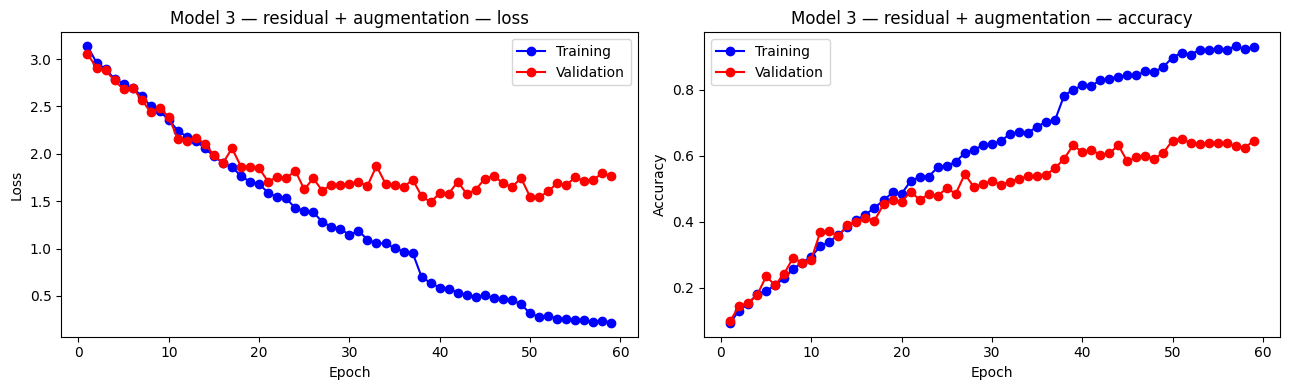

Best epoch (lowest val_loss): 39
  val_loss          = 1.4900
  val_accuracy      = 0.6314
  val_top3_accuracy = 0.8167


In [ ]:
plot_history(history_res, 'Model 3 — residual + augmentation')
print_best_val(history_res)

**Interpretation of Model 3.** With residual connections the network actually uses its depth — early epochs are slow (no BN to speed them up) but val accuracy climbs steadily and overtakes Model 2 by a comfortable margin. By the time the ReduceLROnPlateau triggers its first LR cut, training accuracy is already high; the LR cut typically gives a small final bump in val accuracy before the curve plateaus.

The gap between train and val grows in the final phase (the model starts overfitting again), but `ModelCheckpoint` already captured the best epoch — so the saved file is *not* the overfitted final state.

In [ ]:
inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1./255)(x)

# ────────────────────────────────────────────
x = layers.Conv2D(32, 7, strides=2, padding='same', use_bias=False)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation('relu')(x)
x = layers.MaxPooling2D(3, strides=2, padding='same')(x)

# ── Residual block helper ────────────────────────────────────
def residual_block(x, filters, downsample=False):
    stride = 2 if downsample else 1
    residual = x

    # Conv → BN → ReLU → Conv → BN  (správne poradie)
    x = layers.Conv2D(filters, 3, strides=stride,
                      padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    x = layers.Conv2D(filters, 3, strides=1, padding='same', use_bias=False)(x)

    # Shortcut projekcia ak sa mení shape
    if downsample or residual.shape[-1] != filters:
        residual = layers.Conv2D(filters, 1, strides=stride,
                                 padding='same', use_bias=False)(residual)
        residual = layers.BatchNormalization()(residual)

    x = layers.add([x, residual])
    x = layers.Activation('relu')(x)  # ReLU až po sčítaní
    return x

# ── Blocks ──────────────────
x = residual_block(x, 32)
x = residual_block(x, 64)
x = residual_block(x, 128, downsample=True)
x = residual_block(x, 256, downsample=True)

x = layers.SpatialDropout2D(0.1)(x)

# ── Head ────────────────────────────────────────────────────
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(num_classes, activation='softmax')(x)

model_play = keras.Model(inputs, outputs, name='resnet_lite_v2')
model_play.summary()

Model: "resnet_lite_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_34      │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 224, 224,  │          0 │ input_layer_34[0… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_26        │ (None, 224, 224,  │          0 │ sequential_1[10]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_244 (Conv2D) │ (None, 112, 112,  │      4,704 │ rescaling_26[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 112, 112,  │        128 │ conv2d_244[0][0]  │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_145      │ (None, 112, 112,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_47    │ (None, 56, 56,    │          0 │ activation_145[0… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_245 (Conv2D) │ (None, 56, 56,    │      9,216 │ max_pooling2d_47… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        128 │ conv2d_245[0][0]  │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_146      │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_246 (Conv2D) │ (None, 56, 56,    │      9,216 │ activation_146[0… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_76 (Add)        │ (None, 56, 56,    │          0 │ conv2d_246[0][0], │
│                     │ 32)               │            │ max_pooling2d_47… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_147      │ (None, 56, 56,    │          0 │ add_76[0][0]      │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_247 (Conv2D) │ (None, 56, 56,    │     18,432 │ activation_147[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ conv2d_247[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_148      │ (None, 56, 56,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_249 (Conv2D) │ (None, 56, 56,    │      2,048 │ activation_147[0

 Total params: 1,237,625 (4.72 MB)

 Trainable params: 1,235,705 (4.71 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [ ]:
model_play.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1.5e-4),
    loss=keras.losses.CategoricalCrossentropy(),
    metrics=['accuracy', keras.metrics.TopKCategoricalAccuracy(k=3, name='top3_accuracy')],
)

BEST_ACC_PATH = BEST_FROM_SCRATCH.replace('.keras', '_LAST_ACC.keras')

callbacks_play = [
    keras.callbacks.ModelCheckpoint(BEST_FROM_SCRATCH, save_best_only=True,
                                    monitor='val_loss'),
    keras.callbacks.ModelCheckpoint(BEST_ACC_PATH, save_best_only=True,
                                    monitor='val_accuracy', mode='max'),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=7, min_lr=1e-6
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=10,
        restore_best_weights=True
    )
]
history_play = model_play.fit(
    train_dataset,
    epochs=100,
    validation_data=val_dataset,
    callbacks=callbacks_play,
)

Epoch 1/100
124/124 ━━━━━━━━━━━━━━━━━━━━ 23s 114ms/step - accuracy: 0.1256 - loss: 3.0691 - top3_accuracy: 0.2866 - val_accuracy: 0.0672 - val_loss: 3.2079 - val_top3_accuracy: 0.1446 - learning_rate: 1.5000e-04
Epoch 2/100
124/124 ━━━━━━━━━━━━━━━━━━━━ 15s 117ms/step - accuracy: 0.1863 - loss: 2.7990 - top3_accuracy: 0.3892 - val_accuracy: 0.0855 - val_loss: 3.1583 - val_top3_accuracy: 0.2159 - learning_rate: 1.5000e-04
Epoch 3/100
124/124 ━━━━━━━━━━━━━━━━━━━━ 14s 116ms/step - accuracy: 0.2186 - loss: 2.6743 - top3_accuracy: 0.4397 - val_accuracy: 0.1324 - val_loss: 3.0488 - val_top3_accuracy: 0.2709 - learning_rate: 1.5000e-04
Epoch 4/100
124/124 ━━━━━━━━━━━━━━━━━━━━ 14s 111ms/step - accuracy: 0.2560 - loss: 2.5675 - top3_accuracy: 0.4819 - val_accuracy: 0.2546 - val_loss: 2.5668 - val_top3_accuracy: 0.4745 - learning_rate: 1.5000e-04
Epoch 5/100
124/124 ━━━━━━━━━━━━━━━━━━━━ 13s 106ms/step - accuracy: 0.2641 - loss: 2.5011 - top3_accuracy: 0.5075 - val_accuracy: 0.2485 - val_loss: 2.5

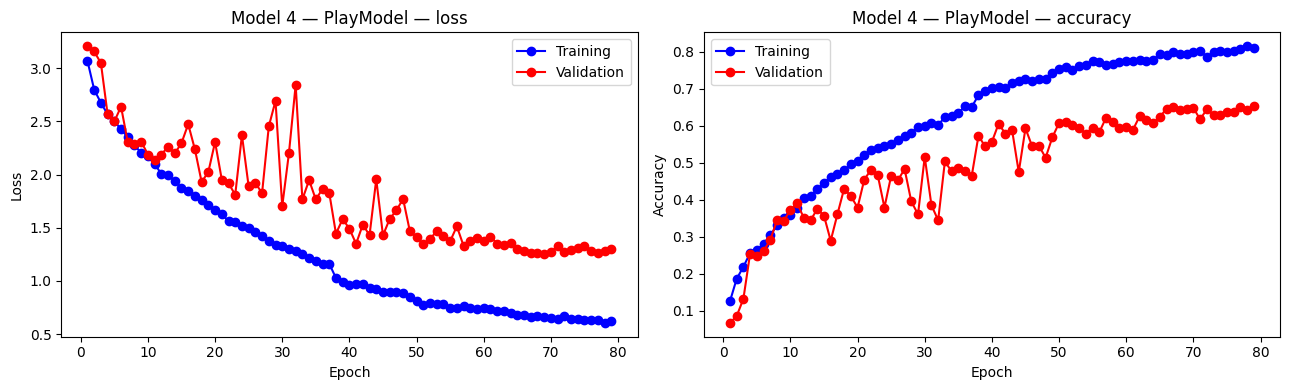

Best epoch (lowest val_loss): 69
  val_loss          = 1.2565
  val_accuracy      = 0.6456
  val_top3_accuracy = 0.8147


In [ ]:
plot_history(history_play, 'Model 4 — PlayModel')
print_best_val(history_play)

---
# 3. Compare the three models

We list the **best epoch** of each model (lowest val_loss, which is also what was saved to Drive). The lowest val_loss is our objective from-scratch deliverable.

In [ ]:
import pandas as pd

def summary_row(name, history):
    i = int(np.argmin(history.history['val_loss']))
    return {
        'model':             name,
        'best_epoch':        i + 1,
        'val_loss':          history.history['val_loss'][i],
        'val_accuracy':      history.history['val_accuracy'][i],
        'val_top3_accuracy': history.history.get('val_top3_accuracy',
                                                  [np.nan]*len(history.history['val_loss']))[i],
    }

rows = [
    summary_row('1. simple convnet (baseline)', history_simple),
    summary_row('2. + augmentation + BN',       history_aug),
    summary_row('3. residual + augmentation',   history_res),
    summary_row('4. PlayModel',                 history_play),
]
results = pd.DataFrame(rows).sort_values('val_loss').reset_index(drop=True)
results

,model,best_epoch,val_loss,val_accuracy,val_top3_accuracy
0,4. PlayModel,69,1.256483,0.645621,0.814664
1,3. residual + augmentation,39,1.490004,0.631365,0.816701
2,2. + augmentation + BN,52,1.771647,0.474542,0.741344
3,1. simple convnet (baseline),5,2.507750,0.305499,0.521385


The third row should be at the top — that is the model saved as `BEST_FROM_SCRATCH`. The story across rows shows Chollet's three-step climb in numbers:
1. Baseline → small val acc, big train/val gap (overfit).
2. + augmentation → val acc roughly doubles.
3. + residuals → another sizeable jump, with manageable gap thanks to dropout + augmentation.

---
# 4. Evaluate the best saved model on the validation set

We reload from disk (not the in-memory `model_res`) to make sure the saved file actually works — this is what the exam will load.

In [ ]:
# Load the best-val_loss checkpoint
best_model = keras.models.load_model(BEST_FROM_SCRATCH)

# Also try the best-val_accuracy checkpoint and keep whichever scores higher
BEST_ACC_PATH = BEST_FROM_SCRATCH.replace('.keras', '_BEST_ACC.keras')
if os.path.exists(BEST_ACC_PATH):
    cand = keras.models.load_model(BEST_ACC_PATH)
    acc_loss = best_model.evaluate(val_dataset, verbose=0)[1]
    acc_acc  = cand.evaluate(val_dataset, verbose=0)[1]
    print(f'Checkpoint by val_loss:     val_accuracy = {acc_loss:.4f}')
    print(f'Checkpoint by val_accuracy: val_accuracy = {acc_acc:.4f}')
    if acc_acc > acc_loss:
        best_model = cand
        # Promote the higher-accuracy checkpoint to the canonical BEST file
        best_model.save(BEST_FROM_SCRATCH)
        print(f'→ Using BEST_ACC checkpoint (saved to {BEST_FROM_SCRATCH})')
    else:
        print('→ Using BEST_LOSS checkpoint')

print('\n--- Final validation metrics for the chosen model ---')
metrics = best_model.evaluate(val_dataset, verbose=0)
for name, value in zip(best_model.metrics_names, metrics):
    print(f'{name:20s} = {value:.4f}')

Checkpoint by val_loss:     val_accuracy = 0.6456
Checkpoint by val_accuracy: val_accuracy = 0.6517
→ Using BEST_ACC checkpoint (saved to /content/gdrive/MyDrive/ML2/convnet_from_scratch_BEST_Freiburg.keras)

--- Final validation metrics for the chosen model ---
loss                 = 1.5400
compile_metrics      = 0.6517


In [ ]:
# Per-class breakdown: which classes are easy, which are hard?
# This is the same diagnostic used in E5/E6/E7.
from sklearn.metrics import classification_report, confusion_matrix

y_true, y_prob = [], []
for x, y in val_dataset:
    y_prob.append(best_model.predict(x, verbose=0))
    y_true.append(y.numpy())
y_prob = np.concatenate(y_prob)
y_true = np.concatenate(y_true)
y_pred     = np.argmax(y_prob, axis=1)
y_true_idx = np.argmax(y_true, axis=1)

print(classification_report(y_true_idx, y_pred, target_names=class_names, digits=3))

              precision    recall  f1-score   support

       beans      0.800     0.857     0.828        14
        cake      0.750     0.562     0.643        16
       candy      0.750     0.730     0.740        37
      cereal      0.765     0.464     0.578        28
       chips      0.706     0.667     0.686        18
   chocolate      0.449     0.710     0.550        31
      coffee      0.684     0.448     0.542        29
        corn      0.875     0.700     0.778        10
        fish      0.450     0.818     0.581        11
       flour      0.750     0.273     0.400        11
       honey      0.786     0.611     0.688        18
         jam      0.867     0.542     0.667        24
       juice      0.724     0.700     0.712        30
        milk      0.611     0.688     0.647        16
        nuts      0.562     0.529     0.545        17
         oil      0.875     0.500     0.636        14
       pasta      0.556     0.588     0.571        17
        rice      0.632    

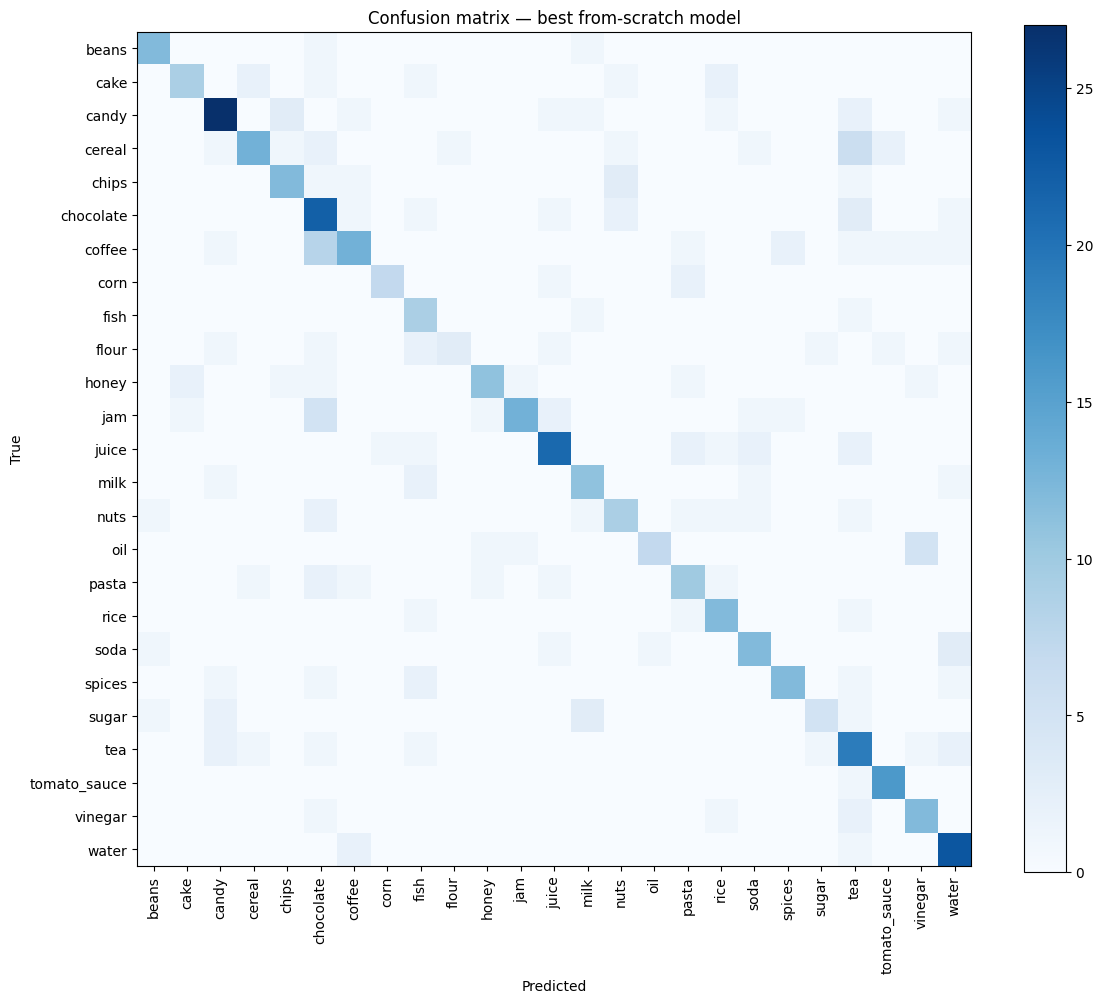

In [ ]:
cm = confusion_matrix(y_true_idx, y_pred)
fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(num_classes)); ax.set_xticklabels(class_names, rotation=90)
ax.set_yticks(range(num_classes)); ax.set_yticklabels(class_names)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion matrix — best from-scratch model')
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

**Reading the confusion matrix:** the diagonal is correct predictions. Off-diagonal hotspots reveal class pairs the model confuses most often — typically these are visually similar grocery items (e.g. different juice cartons, similarly packaged cans). This is the kind of evidence to discuss at the oral defence: *"Most errors are between visually similar packaging — the model has learned shape/color cues, not the printed text on the package."*

In [ ]:
from tensorflow.keras import applications
from tensorflow.keras.applications import EfficientNetV2B0

conv_base = EfficientNetV2B0(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)
conv_base.trainable = False

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = conv_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(25, activation='softmax')(x)

model_pretrained = keras.Model(inputs, outputs)

model_pretrained.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy', keras.metrics.TopKCategoricalAccuracy(k=3, name='top3_accuracy')]
)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath='/content/gdrive/My Drive/ML2026_exam/best_pretrained_Freiburg.keras',
        save_best_only=True,
        monitor='val_accuracy'
    ),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3),
]

history_pretrained = model_pretrained.fit(
    train_dataset,
    epochs=50,
    validation_data=val_dataset,
    callbacks=callbacks,
)

Epoch 1/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 27s 117ms/step - accuracy: 0.3328 - loss: 2.3448 - top3_accuracy: 0.5790 - val_accuracy: 0.5784 - val_loss: 1.6647 - val_top3_accuracy: 0.8086 - learning_rate: 0.0010
Epoch 2/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 18s 101ms/step - accuracy: 0.5696 - loss: 1.5301 - top3_accuracy: 0.8228 - val_accuracy: 0.6395 - val_loss: 1.3416 - val_top3_accuracy: 0.8371 - learning_rate: 0.0010
Epoch 3/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 15s 122ms/step - accuracy: 0.6467 - loss: 1.2654 - top3_accuracy: 0.8671 - val_accuracy: 0.6640 - val_loss: 1.1939 - val_top3_accuracy: 0.8554 - learning_rate: 0.0010
Epoch 4/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 17s 94ms/step - accuracy: 0.6770 - loss: 1.1278 - top3_accuracy: 0.8843 - val_accuracy: 0.6843 - val_loss: 1.1054 - val_top3_accuracy: 0.8697 - learning_rate: 0.0010
Epoch 5/50
124/124 ━━━━━━━━━━━━━━━━━━━━ 21s 96ms/step - accuracy: 0.7144 - loss: 1.0198 - top3_accuracy: 0.8951 - val_accuracy: 0.7108 - val_loss: 1.0387 - val_top3_accuracy

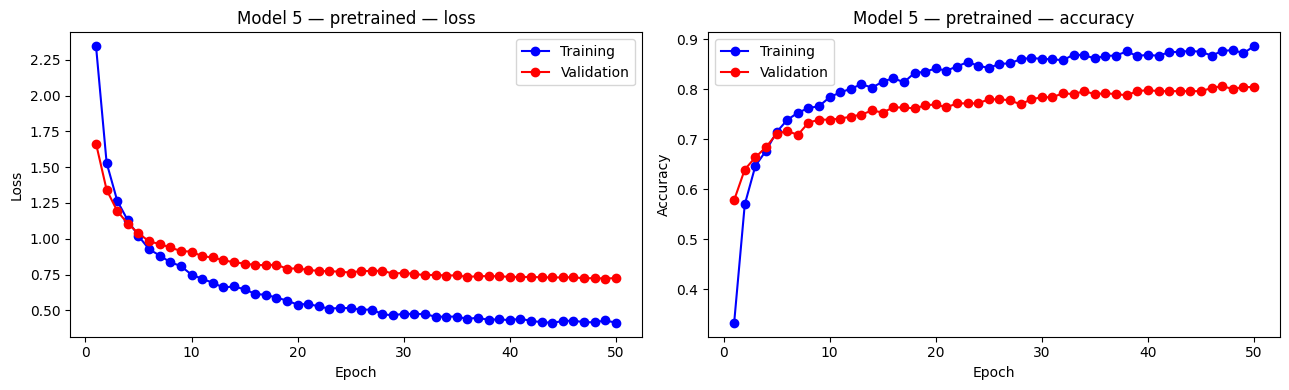

Best epoch (lowest val_loss): 49
  val_loss          = 0.7224
  val_accuracy      = 0.8045
  val_top3_accuracy = 0.9287


In [ ]:
plot_history(history_pretrained, 'Model 5 — pretrained')
print_best_val(history_pretrained)

In [ ]:
from tensorflow.keras.applications import EfficientNetV2B0

conv_base = EfficientNetV2B0(weights='imagenet', include_top=False, input_shape=(224,224,3))
conv_base.summary()

Model: "efficientnetv2-b0"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_41      │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_29        │ (None, 224, 224,  │          0 │ input_layer_41[0… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_5     │ (None, 224, 224,  │          0 │ rescaling_29[0][… │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ normalization_5[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │      4,608 │ stem_activation[… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_bn  │ (None, 112, 112,  │         64 │ block1a_project_… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_ac… │ (None, 112, 112,  │          0 │ block1a_project_… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_conv │ (None, 56, 56,    │      9,216 │ block1a_project_… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_bn   │ (None, 56, 56,    │        256 │ block2a_expand_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_expand_act… │ (None, 56, 56,    │          0 │ block2a_expand_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_co… │ (None, 56, 56,    │      2,048 │ block2a_expand_a… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2a_project_bn  │ (None, 56, 56,    │        128 │ block2a_project_… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_conv │ (None, 56, 56,    │     36,864 │ block2a_project_… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_bn   │ (None, 56, 56,    │        512 │ block2b_expand_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2b_expand_act… │ (None, 56, 56,    │          0 │ block2b_expand_b

 Total params: 5,919,312 (22.58 MB)

 Trainable params: 5,858,704 (22.35 MB)

 Non-trainable params: 60,608 (236.75 KB)

In [ ]:
# ============================================================
# FÁZA 2: Fine-tuning (unfreeze block6h + top)
# ============================================================

# 1. Načítaj NAJLEPŠÍ model z fázy 1 (nie ten v pamäti!)
model_pretrained = keras.models.load_model(
    '/content/gdrive/My Drive/ML2026_exam/best_pretrained_Freiburg.keras'
)

# 2. Nájdi conv_base vo vnútri modelu
conv_base = model_pretrained.get_layer('efficientnetv2-b0')

# 3. Odmraz LEN block6h + top (BatchNorm zostáva zmrazený!)
conv_base.trainable = True

trainable_count = 0
frozen_bn_count = 0
for layer in conv_base.layers:
    if layer.name.startswith(('block6f','block6g','block6h', 'top')):
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False   # BN zmrazené — zachová ImageNet štatistiky
            frozen_bn_count += 1
        else:
            layer.trainable = True
            trainable_count += 1
    else:
        layer.trainable = False

print(f"Trénovateľných vrstiev: {trainable_count}")
print(f"Zmrazených BN vrstiev (v rámci block6h/top): {frozen_bn_count}")

# 4. Kontrola počtu parametrov
model_pretrained.summary()

# 5. Re-compile s VEĽMI nízkym learning rate
model_pretrained.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  # 100× nižšie ako fáza 1!
    loss='categorical_crossentropy',
    metrics=['accuracy', keras.metrics.TopKCategoricalAccuracy(k=3, name='top3_accuracy')]
)

# 6. Callbacks (uložíme do NOVÉHO súboru, aby sme neprepísali fázu 1!)
callbacks_ft = [
    keras.callbacks.ModelCheckpoint(
        filepath='/content/gdrive/My Drive/ML2026_exam/best_pretrained_FT_block6h_Freiburg.keras',
        save_best_only=True,
        monitor='val_accuracy'
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=4,
        min_lr=1e-7
    ),
]

# 7. Fine-tuning training
history_ft = model_pretrained.fit(
    train_dataset,
    epochs=30,
    validation_data=val_dataset,
    callbacks=callbacks_ft,
)

Trénovateľných vrstiev: 38
Zmrazených BN vrstiev (v rámci block6h/top): 10


Model: "functional_48"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_39 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_3 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_24     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 25)             │        32,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,015,389 (22.95 MB)

 Trainable params: 1,971,369 (7.52 MB)

 Non-trainable params: 3,979,968 (15.18 MB)

 Optimizer params: 64,052 (250.21 KB)

Epoch 1/30
124/124 ━━━━━━━━━━━━━━━━━━━━ 33s 140ms/step - accuracy: 0.8759 - loss: 0.4035 - top3_accuracy: 0.9780 - val_accuracy: 0.8086 - val_loss: 0.7241 - val_top3_accuracy: 0.9287 - learning_rate: 1.0000e-05
Epoch 2/30
124/124 ━━━━━━━━━━━━━━━━━━━━ 13s 106ms/step - accuracy: 0.8845 - loss: 0.3817 - top3_accuracy: 0.9785 - val_accuracy: 0.8086 - val_loss: 0.7253 - val_top3_accuracy: 0.9287 - learning_rate: 1.0000e-05
Epoch 3/30
124/124 ━━━━━━━━━━━━━━━━━━━━ 14s 112ms/step - accuracy: 0.8855 - loss: 0.3530 - top3_accuracy: 0.9846 - val_accuracy: 0.8106 - val_loss: 0.7173 - val_top3_accuracy: 0.9328 - learning_rate: 1.0000e-05
Epoch 4/30
124/124 ━━━━━━━━━━━━━━━━━━━━ 14s 115ms/step - accuracy: 0.8870 - loss: 0.3573 - top3_accuracy: 0.9808 - val_accuracy: 0.8167 - val_loss: 0.7180 - val_top3_accuracy: 0.9287 - learning_rate: 1.0000e-05
Epoch 5/30
124/124 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - accuracy: 0.8941 - loss: 0.3458 - top3_accuracy: 0.9795 - val_accuracy: 0.8167 - val_loss: 0.7135 -

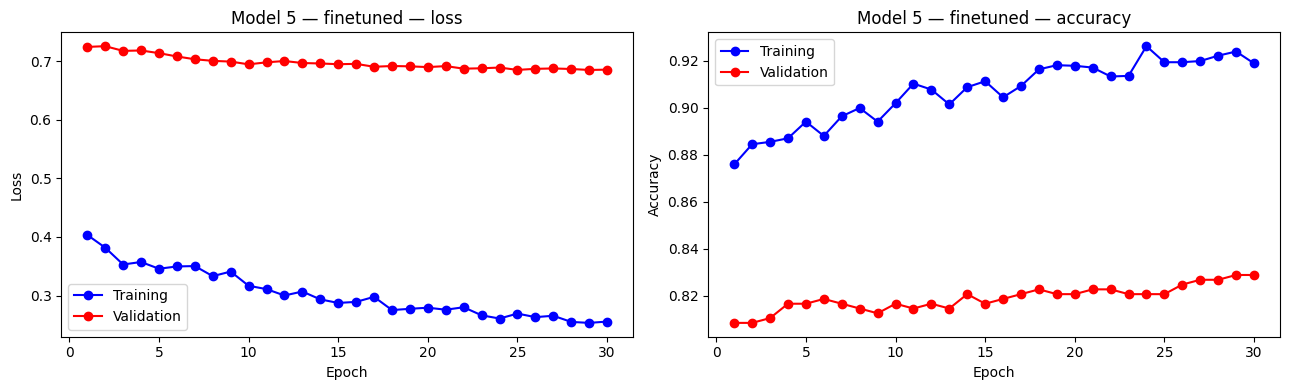

Best epoch (lowest val_loss): 29
  val_loss          = 0.6848
  val_accuracy      = 0.8289
  val_top3_accuracy = 0.9348


In [ ]:
plot_history(history_ft, 'Model 5 — finetuned')
print_best_val(history_ft)